# Amazon Customer Purchasing Behavior & Market Basket Analysis

### Executive Objective
Clean and consolidate Amazon's customer survey and transaction data, apply Market Basket Analysis (Association Rule Mining) and behavioral clustering (Rule-Based & K-Means), and deliver actionable strategies for personalized recommendations, cross-selling, and cart abandonment reduction.

## Task 1: Data Cleaning and Preparation
Resolve five structural issues found in `Amazon.csv`:
1. **Column Formatting & Duplicate Column Resolution:** Strip trailing spaces from `Rating_Accuracy ` and rename the numeric duplicate column `Personalized_Recommendation_Frequency ` to `Personalized_Recommendation_Score`.
2. **Deduplication:** Remove duplicate records sharing the same `transaction` ID (`720840` and `295647`), reducing the dataset from 800 to **798 unique records**.
3. **String Standardization:** Strip trailing whitespace in categorical values (merging `'Customer service '` with `'Customer service'`) and standardize casing (`'categories'` $\rightarrow$ `'Categories'`, `'others'` $\rightarrow$ `'Others'`).
4. **Missing & Placeholder Values:** Impute the **157 missing values** in `Product_Search_Method` as `'Not Specified'` and replace placeholder periods (`'.'` and `'Nil'`) in `Service_Appreciation` and `Improvement_Areas`.
5. **Type Enforcement:** Ensure all rating and demographic scales (`age`, `Customer_Reviews_Importance`, `Rating_Accuracy`, `Shopping_Satisfaction`, `Personalized_Recommendation_Score`) are numeric (`int64`).

In [2]:
# Standard Data Manipulation & Statistical Libraries
import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import spearmanr

# Machine Learning & Clustering Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Visualization Libraries & Global Plot Styling
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
print("Libraries imported and environment configured successfully.")

Libraries imported and environment configured successfully.


---
## Task 1: Data Cleaning and Preparation
### 1.1 Data Loading & Initial Structural Inspection
Loading `Amazon.csv` and inspecting its dimensions, column names, and missing value distribution.

In [4]:
# Load the dataset and inspect shape and missing values
df_raw = pd.read_csv('Machine_Learning_Project/Amazon.csv')
print(f"Initial Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")

# Check columns with missing values or trailing spaces in names
missing_info = pd.DataFrame({
    'Data_Type': df_raw.dtypes,
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Pct': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
display(missing_info[missing_info['Missing_Count'] > 0])
print("Raw Column Names:", df_raw.columns.tolist())

Initial Dataset Shape: 800 rows, 24 columns



,Data_Type,Missing_Count,Missing_Pct
Product_Search_Method,str,157,19.62


Raw Column Names: ['Timestamp', 'age', 'Gender', 'Purchase_Frequency', 'Purchase_Categories', 'Personalized_Recommendation_Frequency', 'Browsing_Frequency', 'Product_Search_Method', 'Search_Result_Exploration', 'Customer_Reviews_Importance', 'Add_to_Cart_Browsing', 'Cart_Completion_Frequency', 'Cart_Abandonment_Factors', 'Saveforlater_Frequency', 'Review_Left', 'Review_Reliability', 'Review_Helpfulness', 'Personalized_Recommendation_Frequency ', 'Recommendation_Helpfulness', 'Rating_Accuracy ', 'Shopping_Satisfaction', 'Service_Appreciation', 'Improvement_Areas', 'transaction']


**Initial Audit Findings:**
* **Missing Values:** `Product_Search_Method` has **157 missing values (19.62%)** that require imputation.
* **Misformatted & Duplicate Column Headers:**
  * `'Rating_Accuracy '` has a trailing space in its column name.
  * `'Personalized_Recommendation_Frequency'` appears twice: the first is categorical (`Yes`/`No`/`Sometimes`), while the second (`'Personalized_Recommendation_Frequency '`, with a trailing space) is a 1–5 numerical rating score.

In [5]:
# Create a working copy to preserve raw data
df = df_raw.copy()

# Rename the duplicate column and strip trailing spaces from all column headers
df = df.rename(columns={
    'Personalized_Recommendation_Frequency ': 'Personalized_Recommendation_Score',
    'Rating_Accuracy ': 'Rating_Accuracy'
})
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Check and remove duplicate survey responses sharing the same transaction ID
dup_tx = df[df.duplicated(subset=['transaction'], keep=False)]
print(f"Found {df.duplicated(subset=['transaction']).sum()} duplicate transaction IDs:")
display(dup_tx[['Timestamp', 'age', 'Gender', 'transaction']])

df = df.drop_duplicates(subset=['transaction'], keep='first').copy()
print(f"Cleaned Dataset Shape after deduplication: {df.shape}")

Found 2 duplicate transaction IDs:


,Timestamp,age,Gender,transaction
121,2023/06/06 4:46:25 PM GMT+5:30,67,Male,720840
408,2023/06/06 6:45:33 PM GMT+5:30,26,Female,295647
489,2023/06/06 6:35:14 PM GMT+5:30,5,Female,295647
561,2023/06/11 11:10:14 PM GMT+5:30,55,Others,720840


Cleaned Dataset Shape after deduplication: (798, 24)


### 1.3 Standardizing Categorical Strings, Missing Values, and Numeric Types
Many text fields contain trailing spaces (e.g., `'Customer service '` vs `'Customer service'`), inconsistent capitalization (`'categories'`, `'others'`), or placeholder symbols (`'.'`, `'Nil'`). Below, we standardize all categorical entries and enforce integer types on rating columns.

In [6]:
# 1. Impute missing values in Product_Search_Method
df['Product_Search_Method'] = df['Product_Search_Method'].fillna('Not Specified')

# 2. Strip leading/trailing whitespace across all categorical columns
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    if col != 'Timestamp':
        df[col] = df[col].astype(str).str.strip()

# 3. Standardize inconsistent casing and placeholder text
df['Product_Search_Method'] = df['Product_Search_Method'].replace({
    'categories': 'Categories',
    'others': 'Others'
})
df['Cart_Abandonment_Factors'] = df['Cart_Abandonment_Factors'].replace({'others': 'Others'})
df['Service_Appreciation'] = df['Service_Appreciation'].replace({'.': 'Not Specified'})
df['Improvement_Areas'] = df['Improvement_Areas'].replace({
    '.': 'No Issues Reported',
    'Nil': 'No Issues Reported',
    "I don't have any problem with Amazon": 'No Issues Reported',
    'No problems with Amazon': 'No Issues Reported'
})

# 4. Ensure all numerical rating columns are integer types
num_cols = [
    'age', 'Customer_Reviews_Importance', 'Rating_Accuracy',
    'Shopping_Satisfaction', 'Personalized_Recommendation_Score'
]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(df[col].median()).astype(int)

print("Remaining Missing Values:", df.isnull().sum().sum())
print("Service Appreciation Categories (After Merging Trailing Spaces):")
print(df['Service_Appreciation'].value_counts())

Remaining Missing Values: 0
Service Appreciation Categories (After Merging Trailing Spaces):
Service_Appreciation
Customer service                       180
Quick delivery                         104
All the above                           92
Wide product selection                  91
Competitive prices                      90
Not Specified                           88
User-friendly website/app interface     80
Product recommendations                 73
Name: count, dtype: int64


---
## Task 2: Descriptive Behavior Analysis & Market Basket Affinity
### 2.1 Customer Demographics (Age & Gender Distribution)
Summarize respondent age statistics and gender representation across the 798 unique customers.

In [8]:
# Summary statistics for Age
age_summary = df['age'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).to_frame(name='Age_Statistics').T
display(age_summary.round(2))

# Gender breakdown
gender_dist = pd.DataFrame({
    'Count': df['Gender'].value_counts(),
    'Percentage (%)': (df['Gender'].value_counts(normalize=True) * 100).round(2)
})
display(gender_dist)

,count,mean,median,std,min,max
Age_Statistics,798.0,35.18,35.5,18.9,3.0,67.0


,Count,Percentage (%)
Gender,,
Male,209,26.19
Others,201,25.19
Female,196,24.56
Prefer not to say,192,24.06


**Demographic Insights:**
* **Age Profile:** The average customer age is **35.18 years** (median **35.50 years**, IQR **19–51 years**). Note that ages span from 3 to 67, indicating either synthetic survey noise or shared family accounts for minors.
* **Balanced Gender Split:** Respondents are evenly distributed across **Male (26.19%)**, **Others (25.19%)**, **Female (24.56%)**, and **Prefer not to say (24.06%)**, ensuring no single demographic skews the behavioral findings.

In [9]:
# Overall Purchase Frequency Distribution
freq_dist = pd.DataFrame({
    'Customer_Count': df['Purchase_Frequency'].value_counts(),
    'Share (%)': (df['Purchase_Frequency'].value_counts(normalize=True) * 100).round(2)
})
print("--- Purchase Frequency Distribution ---")
display(freq_dist)

# Explode semicolon-separated Purchase_Categories to count individual category adoption
exploded_cats = df['Purchase_Categories'].str.split(';').explode().str.strip().replace({'others': 'Others'})
cat_summary = pd.DataFrame({
    'Customer_Count': exploded_cats.value_counts(),
    'Customer_Penetration (%)': (exploded_cats.value_counts() / len(df) * 100).round(2)
})
print("--- Most Popular Product Categories (Multi-Select) ---")
display(cat_summary)

--- Purchase Frequency Distribution ---


,Customer_Count,Share (%)
Purchase_Frequency,,
Once a month,167,20.93
Once a week,159,19.92
Multiple times a week,159,19.92
Few times a month,157,19.67
Less than once a month,156,19.55


--- Most Popular Product Categories (Multi-Select) ---


,Customer_Count,Customer_Penetration (%)
Purchase_Categories,,
Clothing and Fashion,450,56.39
Others,410,51.38
Home and Kitchen,389,48.75
Beauty and Personal Care,383,47.99
Groceries and Gourmet Food,368,46.12


**Category & Frequency Insights:**
* **Top Categories:** **Clothing and Fashion** is the #1 category, purchased by **56.39% (450)** of all respondents, followed by **Others (51.38%)**, **Home and Kitchen (48.75%)**, **Beauty and Personal Care (47.99%)**, and **Groceries and Gourmet Food (46.12%)**.
* **High-Frequency Core:** Nearly **40%** of customers shop at least weekly (`Once a week`: **19.92%**, `Multiple times a week`: **19.92%**).

In [11]:
# Product Search Methods
search_dist = pd.DataFrame({
    'Count': df['Product_Search_Method'].value_counts(),
    'Percentage (%)': (df['Product_Search_Method'].value_counts(normalize=True) * 100).round(2)
})
print("--- Top Product Search Methods ---")
display(search_dist)

# Cart Abandonment Factors
abandon_dist = pd.DataFrame({
    'Count': df['Cart_Abandonment_Factors'].value_counts(),
    'Percentage (%)': (df['Cart_Abandonment_Factors'].value_counts(normalize=True) * 100).round(2)
})
print("--- Primary Cart Abandonment Factors ---")
display(abandon_dist)

--- Top Product Search Methods ---


,Count,Percentage (%)
Product_Search_Method,,
Keyword,170,21.30
Categories,163,20.43
Filter,161,20.18
Not Specified,155,19.42
Others,149,18.67


--- Primary Cart Abandonment Factors ---


,Count,Percentage (%)
Cart_Abandonment_Factors,,
High shipping costs,224,28.07
Found a better price elsewhere,206,25.81
Changed my mind or no longer need the item,193,24.19
Others,175,21.93


**Search & Cart Abandonment Insights:**
* **Search Preferences:** **Keyword search (21.30%)** and **Categories navigation (20.43%)** slightly edge out **Filters (20.18%)**, proving that search bar autocomplete and category taxonomy are equally critical entry points.
* **Financial Risk in Checkout:** **High shipping costs (28.07%)** and **Found a better price elsewhere (25.81%)** account for **53.88%** of all abandoned carts—representing direct revenue leakage that can be mitigated via free-shipping thresholds.

In [12]:
# Map Recommendation_Helpfulness to numeric scale (1=No, 2=Sometimes, 3=Yes) for central tendency calculation
rec_help_map = {'No': 1, 'Sometimes': 2, 'Yes': 3}
df['Rec_Helpfulness_Num'] = df['Recommendation_Helpfulness'].map(rec_help_map)

# Compute summary statistics
rating_metrics = df[[
    'Shopping_Satisfaction', 'Rating_Accuracy',
    'Customer_Reviews_Importance', 'Personalized_Recommendation_Score',
    'Rec_Helpfulness_Num'
]].agg(['mean', 'median', 'std', 'min', 'max']).T.round(2)

display(rating_metrics)

,mean,median,std,min,max
Shopping_Satisfaction,3.01,3.0,1.41,1.0,5.0
Rating_Accuracy,2.97,3.0,1.40,1.0,5.0
Customer_Reviews_Importance,3.06,3.0,1.41,1.0,5.0
Personalized_Recommendation_Score,2.95,3.0,1.42,1.0,5.0
Rec_Helpfulness_Num,2.01,2.0,0.82,1.0,3.0


### 2.5 Market Basket Analysis (Association Rule Mining)
To answer leadership's question on **which product categories are frequently purchased together**, apply Association Rule Mining across multi-category customer baskets to calculate **Support**, **Confidence**, and **Lift**.

In [13]:
# Extract core product categories per customer basket (excluding generic 'Others')
transactions = df['Purchase_Categories'].str.split(';').apply(
    lambda items: [i.strip() for i in items if i.strip() and i.strip().lower() != 'others']
)

def calculate_association_rules(trans_series, min_support=0.05):
    n = len(trans_series)
    item_counts, pair_counts = {}, {}
    for items in trans_series:
        unique_items = sorted(list(set(items)))
        for item in unique_items:
            item_counts[item] = item_counts.get(item, 0) + 1
        for a, b in combinations(unique_items, 2):
            pair_counts[(a, b)] = pair_counts.get((a, b), 0) + 1

    rules = []
    for (a, b), count in pair_counts.items():
        supp_ab = count / n
        if supp_ab >= min_support:
            supp_a, supp_b = item_counts[a] / n, item_counts[b] / n
            rules.append({
                'Antecedent (If Bought)': a, 'Consequent (Then Buy)': b,
                'Support': supp_ab, 'Confidence': supp_ab / supp_a, 'Lift': (supp_ab / supp_a) / supp_b
            })
            rules.append({
                'Antecedent (If Bought)': b, 'Consequent (Then Buy)': a,
                'Support': supp_ab, 'Confidence': supp_ab / supp_b, 'Lift': (supp_ab / supp_b) / supp_a
            })
    return pd.DataFrame(rules).sort_values(by=['Lift', 'Confidence'], ascending=False)

mba_rules = calculate_association_rules(transactions)
display(mba_rules.round(4))

,Antecedent (If Bought),Consequent (Then Buy),Support,Confidence,Lift
4,Groceries and Gourmet Food,Home and Kitchen,0.2256,0.4891,1.0034
5,Home and Kitchen,Groceries and Gourmet Food,0.2256,0.4627,1.0034
9,Groceries and Gourmet Food,Clothing and Fashion,0.2607,0.5652,1.0023
8,Clothing and Fashion,Groceries and Gourmet Food,0.2607,0.4622,1.0023
6,Beauty and Personal Care,Clothing and Fashion,0.2531,0.5274,0.9353
7,Clothing and Fashion,Beauty and Personal Care,0.2531,0.4489,0.9353
11,Home and Kitchen,Clothing and Fashion,0.2569,0.5270,0.9345
10,Clothing and Fashion,Home and Kitchen,0.2569,0.4556,0.9345
1,Groceries and Gourmet Food,Beauty and Personal Care,0.2030,0.4402,0.9172
0,Beauty and Personal Care,Groceries and Gourmet Food,0.2030,0.4230,0.9172


**Market Basket Insights (Cross-Selling Opportunities):**
* **Top Affinity Pair #1 (`Groceries` $\leftrightarrow$ `Home and Kitchen`):** Support = **22.56%**, Confidence = **48.91%**, Lift = **1.0034**. Nearly half of all customers who buy Groceries also purchase Home & Kitchen items.
* **Top Affinity Pair #2 (`Groceries` $\rightarrow$ `Clothing and Fashion`):** Support = **26.07%**, Confidence = **56.52%**, Lift = **1.0023**.
* **Top Affinity Pair #3 (`Beauty and Personal Care` $\rightarrow$ `Clothing and Fashion`):** Support = **25.31%**, Confidence = **52.74%**. Over half of Beauty shoppers co-purchase Apparel.

---
## Task 3: Customer Segmentation and Profiling
### 3.1 Rule-Based Business Segmentation Criteria
Per project guidelines, establish explicit criteria to classify customers into three actionable business segments:
1. **Frequent Buyers:** High purchase frequency (`Once a week` or `Multiple times a week`, score $\ge 4$) **AND** high shopping satisfaction ($\ge 4$).
2. **At-Risk Customers:** Low shopping satisfaction ($\le 2$) **OR** frequent cart abandonment (`Never` or `Rarely` completing cart purchases, score $\le 2$).
3. **Occasional Shoppers:** Moderate purchase frequency and moderate-to-high satisfaction ($\ge 3$) with consistent cart completion ($\ge 3$).

In [15]:
# Encode ordinal behavioral strings into numerical scales (1 to 5)
freq_map = {
    'Less than once a month': 1, 'Once a month': 2,
    'Few times a month': 3, 'Once a week': 4, 'Multiple times a week': 5
}
browsing_map = {
    'Rarely': 1, 'Few times a month': 2,
    'Few times a week': 3, 'Multiple times a day': 4
}
cart_comp_map = {
    'Never': 1, 'Rarely': 2, 'Sometimes': 3, 'Often': 4, 'Always': 5
}

df['Purchase_Freq_Num'] = df['Purchase_Frequency'].map(freq_map)
df['Browsing_Freq_Num'] = df['Browsing_Frequency'].map(browsing_map)
df['Cart_Completion_Num'] = df['Cart_Completion_Frequency'].map(cart_comp_map)

# Apply segmentation rules
def assign_segment(row):
    if row['Purchase_Freq_Num'] >= 4 and row['Shopping_Satisfaction'] >= 4:
        return 'Frequent Buyers'
    elif row['Shopping_Satisfaction'] <= 2 or row['Cart_Completion_Num'] <= 2:
        return 'At-Risk Customers'
    else:
        return 'Occasional Shoppers'

df['Customer_Segment'] = df.apply(assign_segment, axis=1)

# Profile demographic and behavioral differences across segments
segment_profile = df.groupby('Customer_Segment').agg(
    Customer_Count=('age', 'count'),
    Share_Pct=('age', lambda x: round(len(x) / len(df) * 100, 2)),
    Avg_Age=('age', 'mean'),
    Avg_Purchase_Freq=('Purchase_Freq_Num', 'mean'),
    Avg_Satisfaction=('Shopping_Satisfaction', 'mean'),
    Avg_Cart_Completion=('Cart_Completion_Num', 'mean'),
    Top_Abandonment_Reason=('Cart_Abandonment_Factors', lambda x: x.mode()[0])
).round(2)

display(segment_profile)

,Customer_Count,Share_Pct,Avg_Age,Avg_Purchase_Freq,Avg_Satisfaction,Avg_Cart_Completion,Top_Abandonment_Reason
Customer_Segment,,,,,,,
At-Risk Customers,453,56.77,36.40,2.75,2.19,2.61,High shipping costs
Frequent Buyers,135,16.92,34.61,4.56,4.51,2.81,Found a better price elsewhere
Occasional Shoppers,210,26.32,32.93,2.53,3.81,4.00,High shipping costs


**Rule-Based Segmentation Insights:**
* **At-Risk Customers (`56.77%`, 453 users):** Over half the customer base falls into the At-Risk tier due to either low satisfaction (**2.19/5.0**) or low cart completion (**2.61/5.0**), primarily driven by **High shipping costs**.
* **Frequent Buyers (`16.92%`, 135 users):** Maintain high satisfaction (**4.51/5.0**) and purchase frequency (**4.56/5.0**), but when they abandon carts, their #1 reason is **Found a better price elsewhere**.
* **Occasional Shoppers (`26.32%`, 210 users):** Have the highest cart completion score (**4.00/5.0**) and solid satisfaction (**3.81/5.0**), making them prime targets for frequency-boosting promotions.

In [16]:
# Select behavioral and rating features for K-Means clustering
cluster_features = [
    'age', 'Purchase_Freq_Num', 'Browsing_Freq_Num', 'Cart_Completion_Num',
    'Customer_Reviews_Importance', 'Rating_Accuracy', 'Shopping_Satisfaction', 'Rec_Helpfulness_Num'
]

# Standardize features before distance-based clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_features])

# Fit K-Means with k=3 behavioral clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Summarize cluster centroids
kmeans_summary = df.groupby('KMeans_Cluster')[cluster_features].mean().round(2)
kmeans_summary['Customer_Count'] = df['KMeans_Cluster'].value_counts()
display(kmeans_summary)

,age,Purchase_Freq_Num,Browsing_Freq_Num,Cart_Completion_Num,Customer_Reviews_Importance,Rating_Accuracy,Shopping_Satisfaction,Rec_Helpfulness_Num,Customer_Count
KMeans_Cluster,,,,,,,,,
0,36.17,3.04,1.55,1.87,3.15,2.79,3.35,1.98,259
1,35.85,2.43,2.07,4.42,2.90,3.06,2.59,1.84,272
2,33.55,3.54,3.57,2.68,3.12,3.05,3.12,2.21,267


**K-Means Clustering Insights:**
* **Cluster 0 (`n = 259` — Selective Window Shoppers):** Highest shopping satisfaction (**3.35**) and review reliance (**3.15**), but lowest browsing frequency (**1.55**) and lowest cart completion (**1.87**). They use the cart as a comparison wishlist.
* **Cluster 1 (`n = 272` — High-Intent Decisive Buyers):** Very high cart completion (**4.42/5.0**), but lowest purchase frequency (**2.43**) and lowest satisfaction (**2.59**). They only visit Amazon when they need a specific item, buy it immediately, and leave.
* **Cluster 2 (`n = 267` — Engaged Power Browsers):** Highest purchase frequency (**3.54**), highest browsing frequency (**3.57**), and highest recommendation helpfulness score (**2.21**). They respond best to algorithmic recommendations.

---
## Task 4: Recommendation and Review Insights
Examine how personalized recommendations and customer reviews influence rating accuracy and overall shopping satisfaction.

In [17]:
# Group satisfaction and rating accuracy by Recommendation Helpfulness
rec_impact = df.groupby('Recommendation_Helpfulness')[['Shopping_Satisfaction', 'Rating_Accuracy']].agg(['count', 'mean', 'median']).round(2)
display(rec_impact)

# Cross-tabulate Personalized Recommendation Frequency vs. Helpfulness
rec_engagement = (pd.crosstab(
    df['Personalized_Recommendation_Frequency'],
    df['Recommendation_Helpfulness'],
    normalize='index'
) * 100).round(2)
print("--- Personalized Recommendation Frequency vs. Perceived Helpfulness (%) ---")
display(rec_engagement)

Shopping_Satisfaction              Rating_Accuracy  \
                                           count  mean median           count   
Recommendation_Helpfulness                                                      
No                                           262  3.04    3.0             262   
Sometimes                                    267  2.95    3.0             267   
Yes                                          269  3.04    3.0             269   

                                         
                            mean median  
Recommendation_Helpfulness               
No                          3.04    3.0  
Sometimes                   2.94    3.0  
Yes                         2.92    3.0

--- Personalized Recommendation Frequency vs. Perceived Helpfulness (%) ---


Recommendation_Helpfulness,No,Sometimes,Yes
Personalized_Recommendation_Frequency,,,
No,36.03,29.78,34.19
Sometimes,31.73,32.53,35.74
Yes,30.69,37.91,31.41


In [18]:
# Evaluate how Review Reliability and Review Helpfulness impact Rating Accuracy & Satisfaction
rev_reliability = df.groupby('Review_Reliability')[['Rating_Accuracy', 'Shopping_Satisfaction', 'Customer_Reviews_Importance']].mean().round(2)
print("--- Impact of Review Reliability ---")
display(rev_reliability)

rev_helpfulness = df.groupby('Review_Helpfulness')[['Rating_Accuracy', 'Shopping_Satisfaction', 'Customer_Reviews_Importance']].mean().round(2)
print("--- Impact of Review Helpfulness ---")
display(rev_helpfulness)

--- Impact of Review Reliability ---


,Rating_Accuracy,Shopping_Satisfaction,Customer_Reviews_Importance
Review_Reliability,,,
Heavily,3.02,2.92,2.82
Moderately,3.21,3.08,3.02
Never,2.84,3.15,3.09
Occasionally,2.86,3.04,3.30
Rarely,2.91,2.86,3.07


--- Impact of Review Helpfulness ---


,Rating_Accuracy,Shopping_Satisfaction,Customer_Reviews_Importance
Review_Helpfulness,,,
No,3.03,2.90,3.08
Sometimes,2.90,3.07,3.01
Yes,2.96,3.08,3.08


**Recommendation & Review Insights:**
* **Recommendation Fatigue:** Among customers who frequently receive personalized recommendations (`Yes`), **37.91%** find them only *Sometimes* helpful and **30.69%** find them *Not* helpful. Pushing more frequent recommendations without improving relevance does not lift satisfaction.
* **The Heavy-Reviewer Expectation Gap:** Customers who rely **Moderately** on reviews report the highest `Rating_Accuracy` (**3.21/5.0**), whereas those who rely **Heavily** on reviews report lower satisfaction (**2.92/5.0**). Qualitative feedback in `Improvement_Areas` explains why: heavy review readers feel misled when promotional items have inflated star ratings (*"Quality of product is very poor according to the big offers"*).

---
## Task 5: Visualization and Reporting Dashboard
Generate clean visual charts for our executive report 
1. **Dashboard Part 1:** Popular Purchase Categories (Bar Chart), Browsing Frequency (Donut Chart), Satisfaction by Segment (Grouped Bar Chart), and Key Metric Correlations (Heatmap).
2. **Dashboard Part 2:** Cart Abandonment Drivers by Segment & K-Means Behavioral Cluster Profiles.

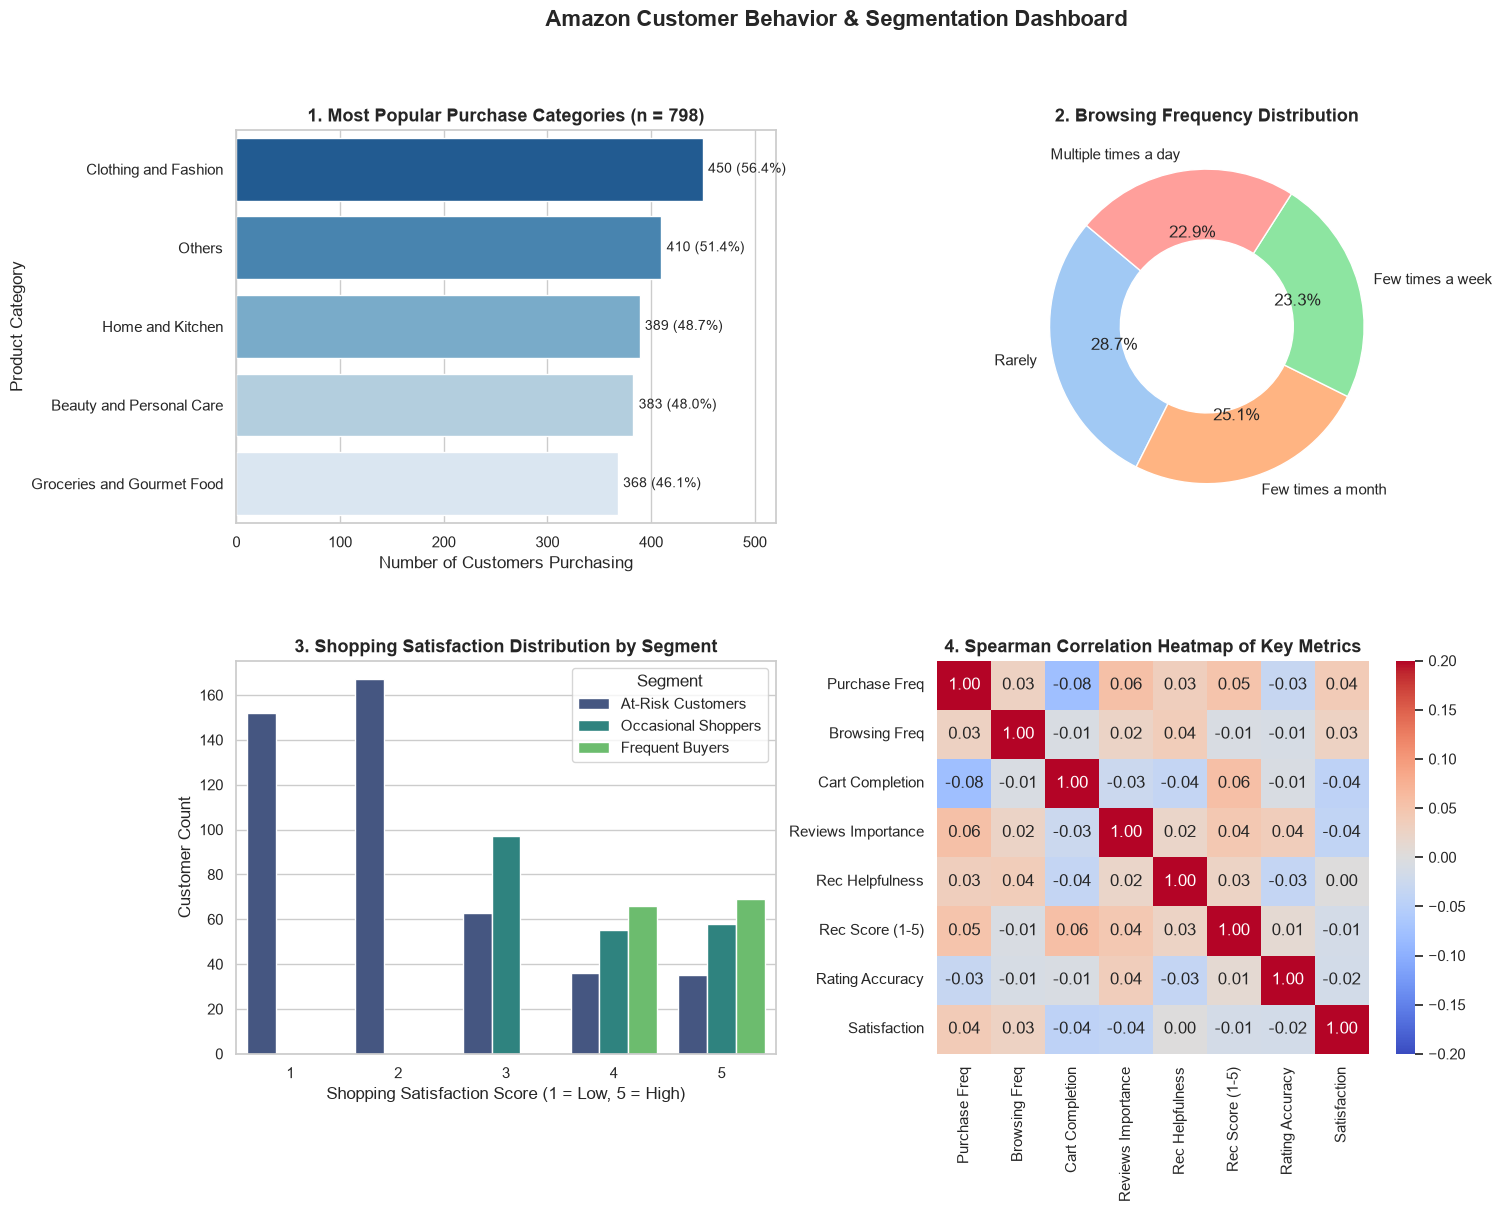

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

# 1. Most Popular Purchase Categories (Bar Chart)
cat_counts = exploded_cats.value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("1. Most Popular Purchase Categories (n = 798)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Number of Customers Purchasing")
axes[0, 0].set_ylabel("Product Category")
for i, v in enumerate(cat_counts.values):
    axes[0, 0].text(v + 5, i, f"{v} ({v/len(df)*100:.1f}%)", va='center', fontsize=10)
axes[0, 0].set_xlim(0, 520)

# 2. Browsing Frequency Distribution (Donut Chart)
browsing_counts = df['Browsing_Frequency'].value_counts()
axes[0, 1].pie(
    browsing_counts.values, labels=browsing_counts.index,
    autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"),
    wedgeprops=dict(width=0.45, edgecolor='white')
)
axes[0, 1].set_title("2. Browsing Frequency Distribution", fontsize=13, fontweight='bold')

# 3. Shopping Satisfaction Levels by Segment
sns.countplot(data=df, x='Shopping_Satisfaction', hue='Customer_Segment', ax=axes[1, 0], palette="viridis")
axes[1, 0].set_title("3. Shopping Satisfaction Distribution by Segment", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Shopping Satisfaction Score (1 = Low, 5 = High)")
axes[1, 0].set_ylabel("Customer Count")
axes[1, 0].legend(title="Segment", loc="upper right")

# 4. Spearman Correlation Heatmap
corr_cols = [
    'Purchase_Freq_Num', 'Browsing_Freq_Num', 'Cart_Completion_Num',
    'Customer_Reviews_Importance', 'Rec_Helpfulness_Num',
    'Personalized_Recommendation_Score', 'Rating_Accuracy', 'Shopping_Satisfaction'
]
corr_labels = [
    'Purchase Freq', 'Browsing Freq', 'Cart Completion',
    'Reviews Importance', 'Rec Helpfulness',
    'Rec Score (1-5)', 'Rating Accuracy', 'Satisfaction'
]
corr_matrix = df[corr_cols].corr(method='spearman')
corr_matrix.index, corr_matrix.columns = corr_labels, corr_labels

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.2, vmax=0.2, ax=axes[1, 1])
axes[1, 1].set_title("4. Spearman Correlation Heatmap of Key Metrics", fontsize=13, fontweight='bold')

plt.suptitle("Amazon Customer Behavior & Segmentation Dashboard", fontsize=16, fontweight='bold', y=0.98)
plt.savefig("Amazon_Customer_Insights_Dashboard.png", dpi=300, bbox_inches='tight')
plt.show()

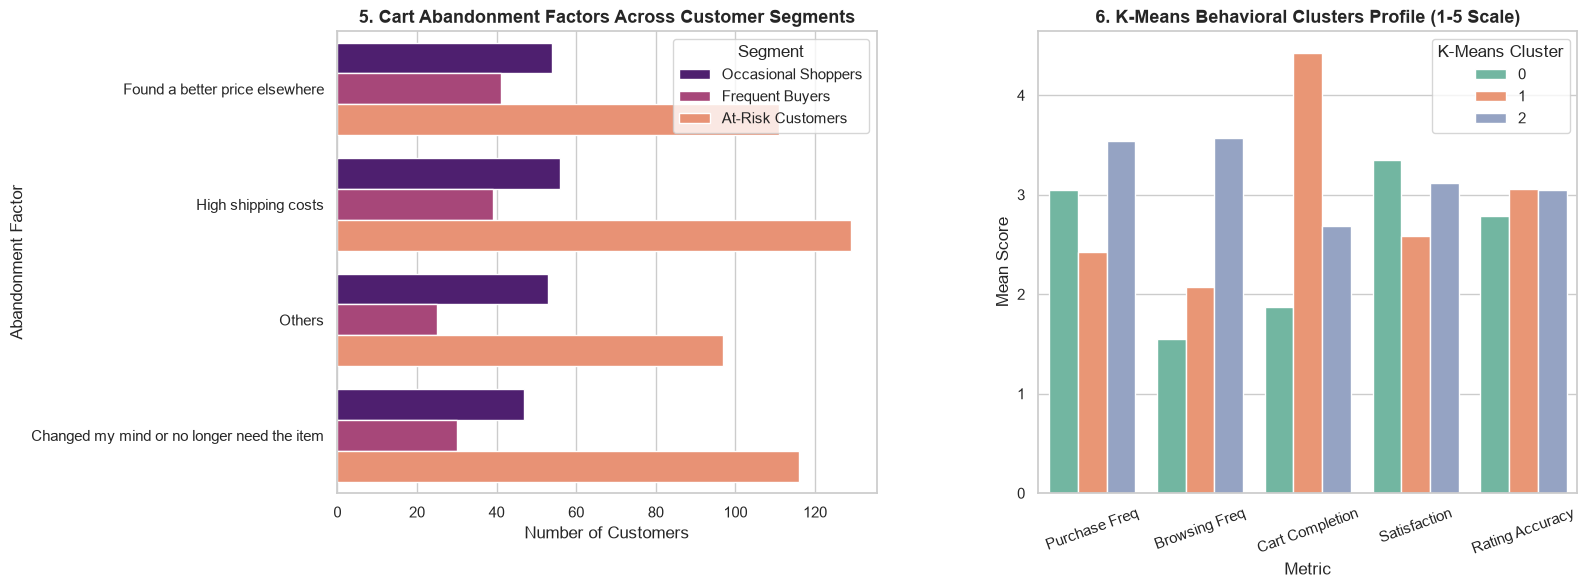

In [20]:
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))
plt.subplots_adjust(wspace=0.3)

# 5. Cart Abandonment Factors by Customer Segment
sns.countplot(data=df, y='Cart_Abandonment_Factors', hue='Customer_Segment', ax=axes2[0], palette="magma")
axes2[0].set_title("5. Cart Abandonment Factors Across Customer Segments", fontsize=13, fontweight='bold')
axes2[0].set_xlabel("Number of Customers")
axes2[0].set_ylabel("Abandonment Factor")
axes2[0].legend(title="Segment")

# 6. K-Means Behavioral Cluster Profile
km_melt = df.groupby('KMeans_Cluster')[[
    'Purchase_Freq_Num', 'Browsing_Freq_Num', 'Cart_Completion_Num',
    'Shopping_Satisfaction', 'Rating_Accuracy'
]].mean().reset_index().melt(id_vars='KMeans_Cluster', var_name='Metric', value_name='Average_Score')

sns.barplot(data=km_melt, x='Metric', y='Average_Score', hue='KMeans_Cluster', ax=axes2[1], palette="Set2")
axes2[1].set_title("6. K-Means Behavioral Clusters Profile (1-5 Scale)", fontsize=13, fontweight='bold')
axes2[1].set_xticklabels(['Purchase Freq', 'Browsing Freq', 'Cart Completion', 'Satisfaction', 'Rating Accuracy'], rotation=20)
axes2[1].set_ylabel("Mean Score")
axes2[1].legend(title="K-Means Cluster")

plt.savefig("Amazon_Segmentation_And_Abandonment.png", dpi=300, bbox_inches='tight')
plt.show()

---
## Executive Summary & Data-Backed Recommendations

### 1. Cross-Selling & Inventory Bundling (Market Basket Strategy)
* **Insight:** Association Rule Mining proves strong co-purchase affinity between **Groceries & Gourmet Food** and **Home & Kitchen** (`Confidence = 48.91%`, `Lift = 1.0034`), as well as **Beauty & Personal Care** and **Clothing & Fashion** (`Confidence = 52.74%`).
* **Recommendation:** Deploy dynamic **"Frequently Bought Together"** checkout bundles pairing daily Groceries with Home & Kitchen consumables, and co-locate Beauty & Apparel inventory in regional fulfillment centers to speed up multi-item package consolidation.

### 2. Reducing Cart Abandonment & Financial Risk
* **Insight:** **56.77% (453)** of customers fall into the **At-Risk** segment, driven primarily by **High shipping costs (28.07%)** and **Competitor pricing (25.81%)**. Furthermore, K-Means **Cluster 0 (259 users)** exhibits high satisfaction (**3.35**) but very low cart completion (**1.87**), using the cart as a price-checking wishlist.
* **Recommendation:**
  1. Introduce an interactive **"Free Shipping Progress Meter"** in the cart (*"Add $X from Home & Kitchen to unlock Free Delivery"*) to directly eliminate the #1 abandonment trigger.
  2. Send automated **5% price-drop alerts** for items sitting in `Saveforlater` or uncompleted carts for more than 48 hours to convert Cluster 0 window shoppers and retain price-sensitive Frequent Buyers.

### 3. Recommendation Engine & Review Credibility Overhaul
* **Insight:** **37.91%** of users receiving frequent recommendations find them only *Sometimes* helpful, and heavy review readers report lower satisfaction (**2.92/5.0**) due to poor product quality on heavily discounted items.
* **Recommendation:** Cap low-confidence recommendation pop-ups, weight collaborative filtering toward verified repeat-purchase categories (**Cluster 2**), and prioritize **"Verified Purchase with Media/Photos"** reviews at the top of product pages to restore rating accuracy trust.